# Rekap & Perbandingan Hasil Eksperimen ABSA

Menggabungkan 4 file hasil cross-validation (`resultsCV1-4.json`) menjadi tabel
perbandingan, file Excel multi-sheet, dan grafik.

**Dua level "skenario":**

| Level | Isi |
|---|---|
| **Konfigurasi (file CV1-CV4)** | kombinasi jumlah data × preprocessing |
| **Skenario balancing** (dalam tiap file) | `none`, `smote`, `tomek`, `smote_tomek` |

Perbedaan tiap konfigurasi:

| Config | Jumlah data | Preprocessing |
|---|---|---|
| **CV1** | 1000 | Tanpa negasi |
| **CV2** | 1000 | Dengan negasi |
| **CV3** | 3000 | Tanpa negasi |
| **CV4** | 3000 | Dengan negasi |

Tiap file berisi 5 aspek (Gameplay & Storyline, Aksesibilitas, Grafis & Performa,
Fitur, Others). Aspek **Others di-skip pada CV1 & CV2** sehingga otomatis dilewati.

## 1. Import & konfigurasi

In [32]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [33]:
import json
import glob
import os

import pandas as pd
import matplotlib.pyplot as plt

# Sesuaikan kalau lokasi file berbeda
INPUT_DIR = "/content/drive/MyDrive/dataset_result"
OUT_DIR = "/content/outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Metadata tiap konfigurasi -> label yang bermakna
CONFIG_META = {
    "S1": {"n_data": 1000, "negasi": "Tanpa negasi"},
    "S2": {"n_data": 1000, "negasi": "Dengan negasi"},
    "S3": {"n_data": 3000, "negasi": "Tanpa negasi"},
    "S4": {"n_data": 3000, "negasi": "Dengan negasi"},
}
def config_label(S):
    m = CONFIG_META[S]
    return f"{S} ({m['n_data']} \u2013 {m['negasi']})"

SCEN_ORDER = ["none", "smote", "tomek", "smote_tomek"]
SCEN_LABEL = {"none": "None", "smote": "SMOTE",
              "tomek": "Tomek", "smote_tomek": "SMOTE+Tomek"}
METRICS = ["accuracy", "precision", "recall", "f1"]

## 2. Baca semua file jadi satu DataFrame (long format)

In [34]:
import glob
import os
import json
import pandas as pd

rows = []
file_paths = sorted(glob.glob(os.path.join(INPUT_DIR, "S*_results.json")))

if not file_paths:
    print(f"[PERINGATAN] Tidak ditemukan file JSON di: {INPUT_DIR}")
    print("Silakan periksa apakah Google Drive sudah ter-mount dengan benar dan path folder sudah sesuai.")
else:
    for path in file_paths:
        # Mengekstrak nama config, misal dari 'S3_results.json' menjadi 'S3'
        cv = os.path.basename(path).replace("_results", "").replace(".json", "")
        data = json.load(open(path))
        meta = CONFIG_META.get(cv, {})

        for acode, ainfo in data.get("aspects", {}).items():
            # Lewati aspek yang di-skip (mis. Others di S1 & S2)
            if not isinstance(ainfo, dict) or ainfo.get("skipped"):
                continue
            alabel = ainfo.get("label", acode)

            for scode, sinfo in ainfo.get("scenarios", {}).items():
                m = sinfo.get("metrics", {})
                std = sinfo.get("metrics_std", {})
                rows.append({
                    "Config": cv,
                    "ConfigLabel": config_label(cv),
                    "Jumlah Data": meta.get("n_data"),
                    "Preprocessing": meta.get("negasi"),
                    "Aspek": alabel,
                    "AspekCode": acode,
                    "Skenario": SCEN_LABEL.get(scode, scode),
                    "SkenarioCode": scode,
                    "accuracy": m.get("accuracy", 0),
                    "precision": m.get("precision", 0),
                    "recall": m.get("recall", 0),
                    "f1": m.get("f1", 0),
                    "f1_std": std.get("f1", 0),
                    "is_best": scode == ainfo.get("best_scenario"),
                })

if rows:
    df = pd.DataFrame(rows)
    df["Skenario"] = pd.Categorical(
        df["Skenario"], [SCEN_LABEL[s] for s in SCEN_ORDER], ordered=True)
    df = df.sort_values(["Config", "Aspek", "Skenario"]).reset_index(drop=True)
    print(f"Total baris: {len(df)}  |  Config: {sorted(df['Config'].unique())}")
    display(df.head(8))
else:
    df = pd.DataFrame() # DataFrame kosong agar cell berikutnya tidak error jika dijalankan
    print("Gagal membuat DataFrame karena tidak ada data yang terproses.")

Total baris: 72  |  Config: ['S1', 'S2', 'S3', 'S4']


,Config,ConfigLabel,Jumlah Data,Preprocessing,Aspek,AspekCode,Skenario,SkenarioCode,accuracy,precision,recall,f1,f1_std,is_best
0,S1,S1 (1000 – Tanpa negasi),1000,Tanpa negasi,Aksesibilitas,a,None,none,0.7437,0.7471,0.7437,0.7423,0.0573,False
1,S1,S1 (1000 – Tanpa negasi),1000,Tanpa negasi,Aksesibilitas,a,SMOTE,smote,0.7745,0.7790,0.7745,0.7740,0.0659,True
2,S1,S1 (1000 – Tanpa negasi),1000,Tanpa negasi,Aksesibilitas,a,Tomek,tomek,0.7551,0.7642,0.7551,0.7524,0.0712,False
3,S1,S1 (1000 – Tanpa negasi),1000,Tanpa negasi,Aksesibilitas,a,SMOTE+Tomek,smote_tomek,0.7664,0.7689,0.7664,0.7659,0.0491,False
4,S1,S1 (1000 – Tanpa negasi),1000,Tanpa negasi,Fitur,f,None,none,0.7237,0.7255,0.7237,0.7206,0.0636,False
5,S1,S1 (1000 – Tanpa negasi),1000,Tanpa negasi,Fitur,f,SMOTE,smote,0.7286,0.7326,0.7286,0.7274,0.0669,False
6,S1,S1 (1000 – Tanpa negasi),1000,Tanpa negasi,Fitur,f,Tomek,tomek,0.7369,0.7361,0.7369,0.7331,0.0349,True
7,S1,S1 (1000 – Tanpa negasi),1000,Tanpa negasi,Fitur,f,SMOTE+Tomek,smote_tomek,0.7286,0.7326,0.7286,0.7274,0.0669,False


## 3. Tabel ringkas

### 3a. F1 terbaik tiap aspek, dibandingkan antar konfigurasi

In [35]:
best = (df[df["is_best"]]
        .pivot_table(index="Aspek", columns="ConfigLabel", values="f1")
        .round(4))
best

ConfigLabel,S1 (1000 – Tanpa negasi),S2 (1000 – Dengan negasi),S3 (3000 – Tanpa negasi),S4 (3000 – Dengan negasi)
Aspek,,,,
Aksesibilitas,0.7740,0.7821,0.8057,0.8018
Fitur,0.7331,0.7465,0.7688,0.8044
Gameplay & Storyline,0.8121,0.8060,0.8814,0.8804
Grafis & Performa,0.7710,0.7585,0.7925,0.8062
Others,NaN,NaN,0.7520,0.7498


### 3b. Efek skenario balancing (rata-rata F1 lintas konfigurasi)

In [36]:
f1_by_scen = (df.pivot_table(index="Aspek", columns="Skenario",
                             values="f1", aggfunc="mean", observed=True)
                .round(4))
f1_by_scen

Skenario,None,SMOTE,Tomek,SMOTE+Tomek
Aspek,,,,
Aksesibilitas,0.7572,0.7876,0.7523,0.7843
Fitur,0.7392,0.7448,0.7526,0.7572
Gameplay & Storyline,0.8399,0.7644,0.8448,0.7904
Grafis & Performa,0.7743,0.7674,0.7802,0.7630
Others,0.7272,0.7228,0.7295,0.7509


### 3c. Efek jumlah data & negasi

Rata-rata F1 (skenario terbaik) dikelompokkan menurut kedua faktor pembeda.

In [37]:
faktor = (df[df["is_best"]]
          .pivot_table(index="Jumlah Data", columns="Preprocessing",
                       values="f1", aggfunc="mean")
          .round(4))
print("Rata-rata F1 terbaik menurut jumlah data x preprocessing:")
faktor

Rata-rata F1 terbaik menurut jumlah data x preprocessing:


Preprocessing,Dengan negasi,Tanpa negasi
Jumlah Data,,
1000,0.7733,0.7726
3000,0.8085,0.8001


## 4. Ekspor ke Excel (multi-sheet)

In [38]:
xlsx_path = os.path.join(OUT_DIR, "perbandingan_skenario.xlsx")
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as xw:
    (df.drop(columns=["AspekCode", "SkenarioCode"])
       .to_excel(xw, sheet_name="Data Lengkap", index=False))
    best.to_excel(xw, sheet_name="F1 Terbaik per Config")
    f1_by_scen.to_excel(xw, sheet_name="F1 per Skenario")
    faktor.to_excel(xw, sheet_name="Efek Data & Negasi")

    # Satu sheet per konfigurasi: F1 aspek x skenario
    for cv in sorted(df["Config"].unique()):
        piv = (df[df["Config"] == cv]
               .pivot_table(index="Aspek", columns="Skenario",
                            values="f1", observed=True).round(4))
        piv.to_excel(xw, sheet_name=cv)

print("Tersimpan:", xlsx_path)

Tersimpan: /content/outputs/perbandingan_skenario.xlsx


## 5. Grafik

### 5a. F1 terbaik tiap aspek antar konfigurasi

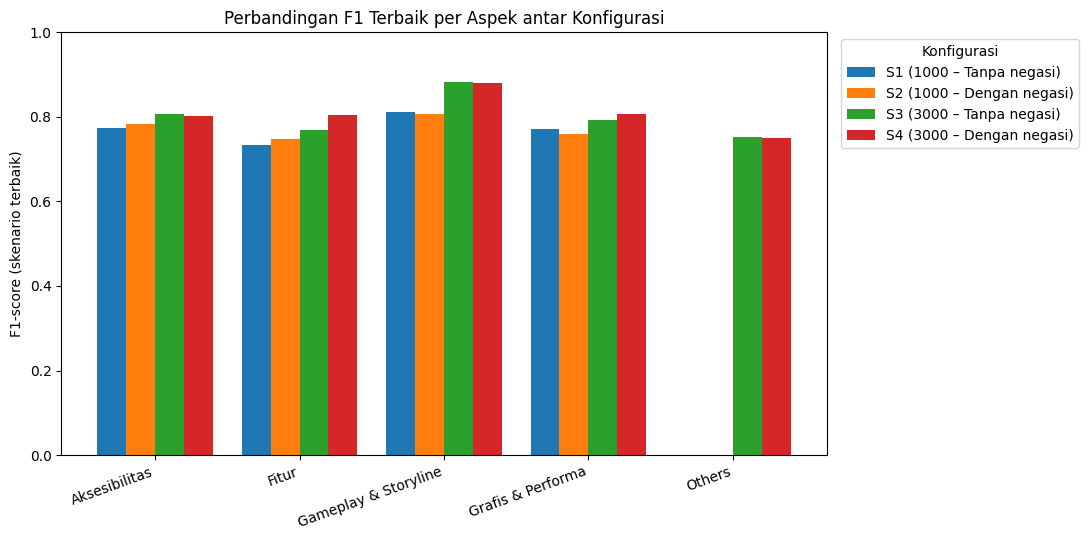

In [39]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})

ax = best.plot(kind="bar", figsize=(11, 5.5), width=0.8)
ax.set_ylabel("F1-score (skenario terbaik)")
ax.set_xlabel("")
ax.set_title("Perbandingan F1 Terbaik per Aspek antar Konfigurasi")
ax.set_ylim(0, 1)
ax.legend(title="Konfigurasi", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "f1_terbaik_per_config.png"), dpi=150)
plt.show()

### 5b. Efek skenario balancing per aspek

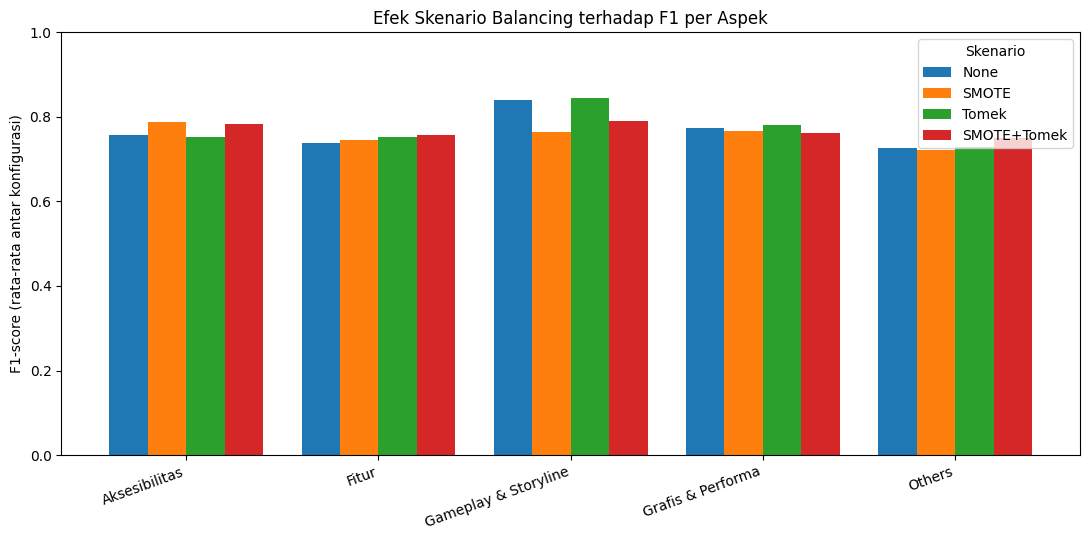

In [40]:
ax = f1_by_scen.plot(kind="bar", figsize=(11, 5.5), width=0.8)
ax.set_ylabel("F1-score (rata-rata antar konfigurasi)")
ax.set_xlabel("")
ax.set_title("Efek Skenario Balancing terhadap F1 per Aspek")
ax.set_ylim(0, 1)
ax.legend(title="Skenario")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "f1_per_skenario.png"), dpi=150)
plt.show()

### 5c. Efek jumlah data & negasi terhadap F1

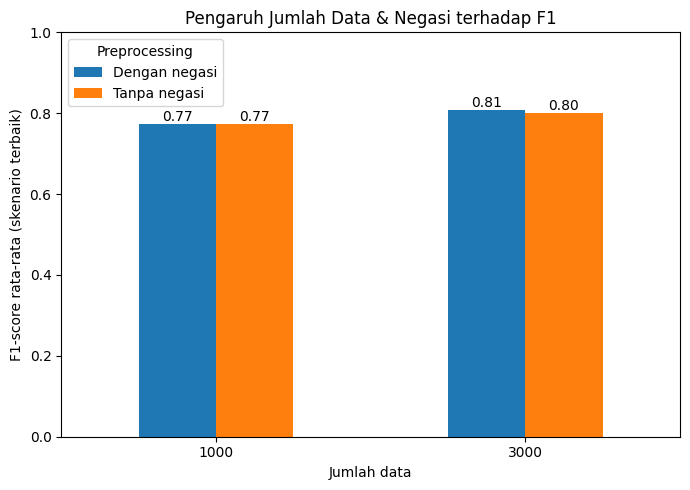

In [41]:
ax = faktor.plot(kind="bar", figsize=(7, 5))
ax.set_ylabel("F1-score rata-rata (skenario terbaik)")
ax.set_xlabel("Jumlah data")
ax.set_title("Pengaruh Jumlah Data & Negasi terhadap F1")
ax.set_ylim(0, 1)
ax.legend(title="Preprocessing")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "efek_data_negasi.png"), dpi=150)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='edge')
plt.show()
plt.show()

## 6. Perbandingan Skenario Balancing (CV1–CV4)

Membandingkan efek keempat skenario balancing (`None`, `SMOTE`, `Tomek`, `SMOTE+Tomek`)
dengan tiga sudut pandang yang saling melengkapi:

| Definisi | Menjawab | Kelebihan / kekurangan |
|---|---|---|
| **6a. Absolut per aspek** | F1 tiap skenario per aspek | Paling jujur, tanpa agregasi — tapi banyak angka |
| **6b. Selisih vs baseline `none`** | Balancing membantu atau merusak? | Adil (tiap aspek vs dirinya sendiri); paling menjawab pertanyaan |
| **6c. Rata-rata makro per config** | Ringkasan satu angka per skenario | Ringkas untuk tabel utama — tapi menyembunyikan variasi antar-aspek |

`none` dipakai sebagai baseline: skenario tanpa penyeimbangan kelas.

### 6a. F1 absolut tiap skenario per aspek

Tiap sel = F1 satu (aspek × skenario) dalam satu config. Tidak ada agregasi.

In [42]:
# Tabel F1 lengkap: baris = (Config, Aspek), kolom = skenario
absolut = (df.pivot_table(index=["ConfigLabel", "Aspek"],
                          columns="Skenario", values="f1", observed=True)
             .round(4))
absolut

Skenario                                          None   SMOTE   Tomek  \
ConfigLabel               Aspek                                          
S1 (1000 – Tanpa negasi)  Aksesibilitas         0.7423  0.7740  0.7524   
                          Fitur                 0.7206  0.7274  0.7331   
                          Gameplay & Storyline  0.8036  0.7305  0.8121   
                          Grafis & Performa     0.7574  0.7648  0.7701   
S2 (1000 – Dengan negasi) Aksesibilitas         0.7582  0.7821  0.7423   
                          Fitur                 0.7465  0.7434  0.7354   
                          Gameplay & Storyline  0.7963  0.7101  0.8060   
                          Grafis & Performa     0.7481  0.7508  0.7522   
S3 (3000 – Tanpa negasi)  Aksesibilitas         0.7633  0.7971  0.7568   
                          Fitur                 0.7375  0.7521  0.7567   
                          Gameplay & Storyline  0.8792  0.8107  0.8814   
                          Grafis & Performa     0.7903  0.7782  0.7925   
                          Others                0.7299  0.7241  0.7340   
S4 (3000 – Dengan negasi) Aksesibilitas         0.7648  0.7971  0.7576   
                          Fitur                 0.7523  0.7561  0.7854   
                          Gameplay & Storyline  0.8804  0.8062  0.8796   
                          Grafis & Performa     0.8013  0.7759  0.8062   
                          Others                0.7245  0.7215  0.7251   

Skenario                                        SMOTE+Tomek  
ConfigLabel               Aspek                              
S1 (1000 – Tanpa negasi)  Aksesibilitas              0.7659  
                          Fitur                      0.7274  
                          Gameplay & Storyline       0.7583  
                          Grafis & Performa          0.7710  
S2 (1000 – Dengan negasi) Aksesibilitas              0.7639  
                          Fitur                      0.7283  
                          Gameplay & Storyline       0.7101  
                          Grafis & Performa          0.7585  
S3 (3000 – Tanpa negasi)  Aksesibilitas              0.8057  
                          Fitur                      0.7688  
                          Gameplay & Storyline       0.8489  
                          Grafis & Performa          0.7641  
                          Others                     0.7520  
S4 (3000 – Dengan negasi) Aksesibilitas              0.8018  
                          Fitur                      0.8044  
                          Gameplay & Storyline       0.8441  
                          Grafis & Performa          0.7586  
                          Others                     0.7498

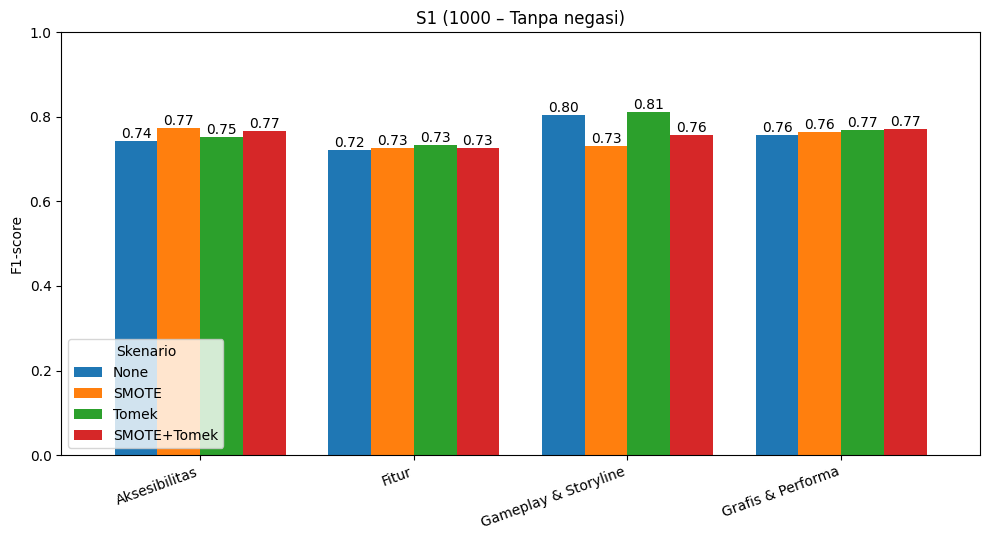

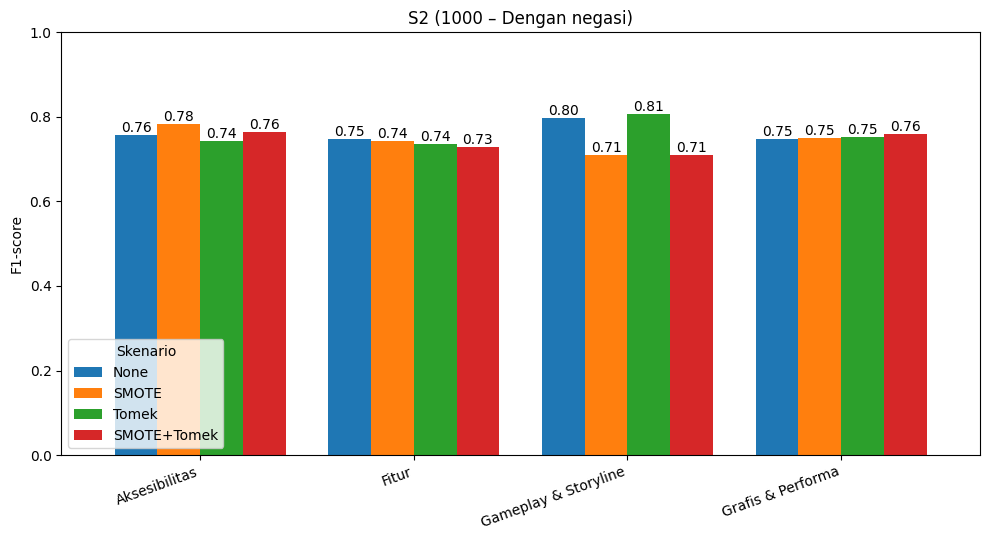

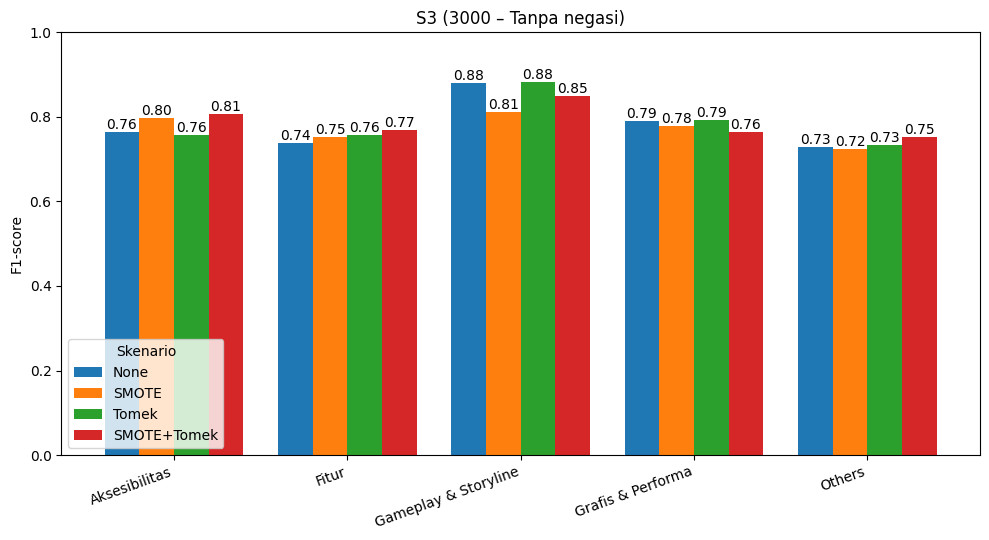

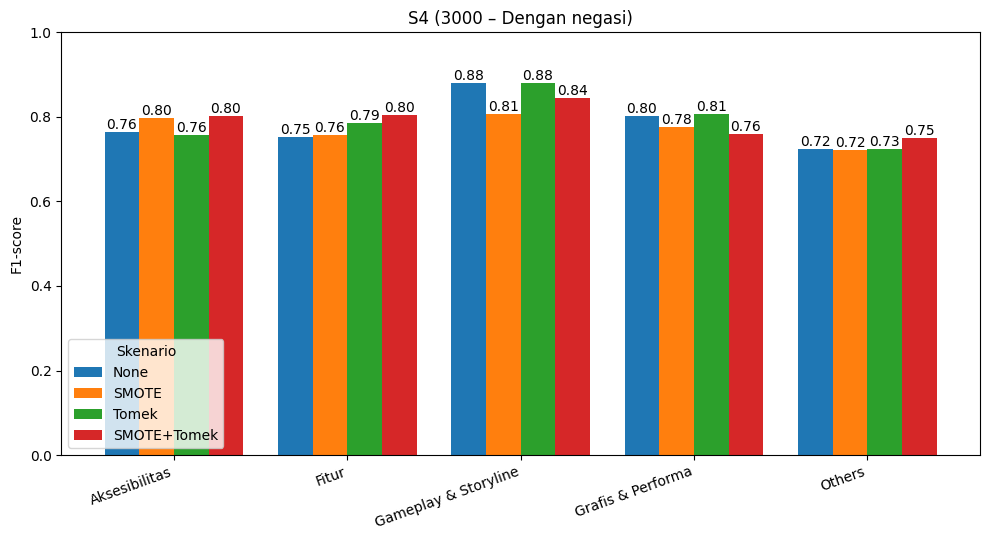

In [43]:
# 6a — satu grafik terpisah per config
for cv in sorted(df["Config"].unique()):
    sub = df[df["Config"] == cv]
    piv = sub.pivot_table(index="Aspek", columns="Skenario",
                          values="f1", observed=True)

    ax = piv.plot(kind="bar", figsize=(10, 5.5), width=0.8)
    ax.set_title(sub["ConfigLabel"].iloc[0], fontsize=12)
    ax.set_xlabel(""); ax.set_ylabel("F1-score"); ax.set_ylim(0, 1)
    ax.legend(title="Skenario")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    for container in ax.containers:
            ax.bar_label(container, fmt='%.2f', label_type='edge')
    plt.savefig(os.path.join(OUT_DIR, f"balancing_absolut_{cv}.png"), dpi=150)
    plt.show()

### 6b. Selisih F1 terhadap baseline `None`  ← analisis utama

Untuk tiap (config × aspek): `ΔF1 = F1(skenario) − F1(None)`.

- **Δ > 0** → balancing **memperbaiki** dibanding tanpa balancing
- **Δ < 0** → balancing **memperburuk**

Baseline `None` sendiri selalu 0 (pembanding), jadi dikeluarkan dari grafik.

In [44]:
# Hitung selisih terhadap None, per (Config, Aspek)
wide = df.pivot_table(index=["Config", "ConfigLabel", "Aspek"],
                      columns="SkenarioCode", values="f1", observed=True)
delta = wide.sub(wide["none"], axis=0).drop(columns="none")
delta.columns = [SCEN_LABEL[c] for c in delta.columns]
delta = delta.round(4)
delta.reset_index().drop(columns="Config")

,ConfigLabel,Aspek,SMOTE,SMOTE+Tomek,Tomek
0,S1 (1000 – Tanpa negasi),Aksesibilitas,0.0317,0.0236,0.0101
1,S1 (1000 – Tanpa negasi),Fitur,0.0068,0.0068,0.0125
2,S1 (1000 – Tanpa negasi),Gameplay & Storyline,-0.0731,-0.0453,0.0085
3,S1 (1000 – Tanpa negasi),Grafis & Performa,0.0074,0.0136,0.0127
4,S2 (1000 – Dengan negasi),Aksesibilitas,0.0239,0.0057,-0.0159
5,S2 (1000 – Dengan negasi),Fitur,-0.0031,-0.0182,-0.0111
6,S2 (1000 – Dengan negasi),Gameplay & Storyline,-0.0862,-0.0862,0.0097
7,S2 (1000 – Dengan negasi),Grafis & Performa,0.0027,0.0104,0.0041
8,S3 (3000 – Tanpa negasi),Aksesibilitas,0.0338,0.0424,-0.0065
9,S3 (3000 – Tanpa negasi),Fitur,0.0146,0.0313,0.0192


In [45]:
# Rata-rata ΔF1 per config x skenario (positif = membantu)
delta_ringkas = (delta.groupby(level="ConfigLabel").mean().round(4))
print("Rata-rata ΔF1 vs None (lintas aspek):")
delta_ringkas

Rata-rata ΔF1 vs None (lintas aspek):


,SMOTE,SMOTE+Tomek,Tomek
ConfigLabel,,,
S1 (1000 – Tanpa negasi),-0.0068,-0.0003,0.0110
S2 (1000 – Dengan negasi),-0.0157,-0.0221,-0.0033
S3 (3000 – Tanpa negasi),-0.0076,0.0079,0.0042
S4 (3000 – Dengan negasi),-0.0133,0.0071,0.0061


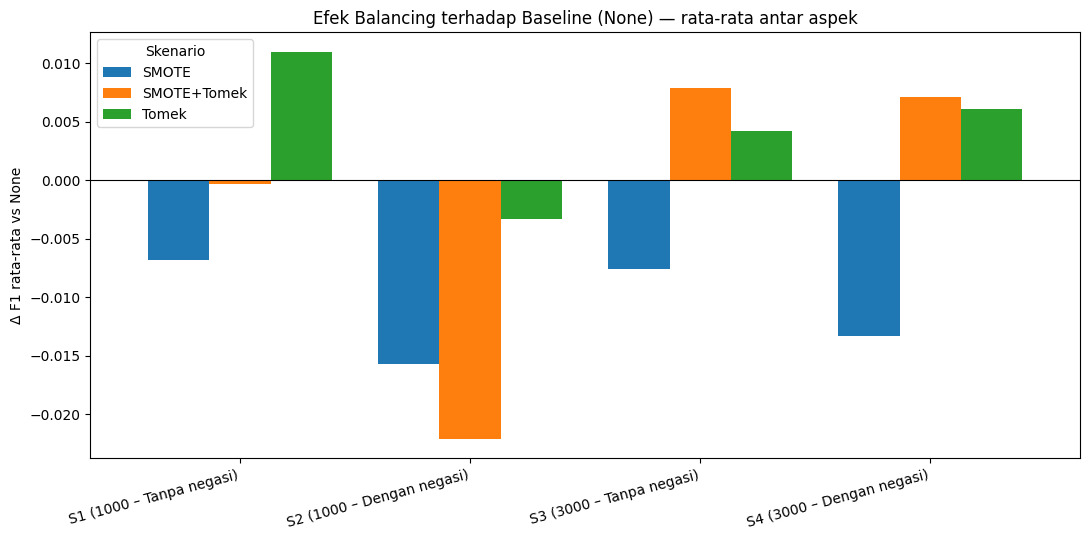

In [46]:
# Grafik: rata-rata ΔF1 per skenario, dikelompokkan per config
ax = delta_ringkas.plot(kind="bar", figsize=(11, 5.5), width=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Δ F1 rata-rata vs None")
ax.set_xlabel("")
ax.set_title("Efek Balancing terhadap Baseline (None) — rata-rata antar aspek")
ax.legend(title="Skenario")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "balancing_delta_vs_none.png"), dpi=150)
plt.show()

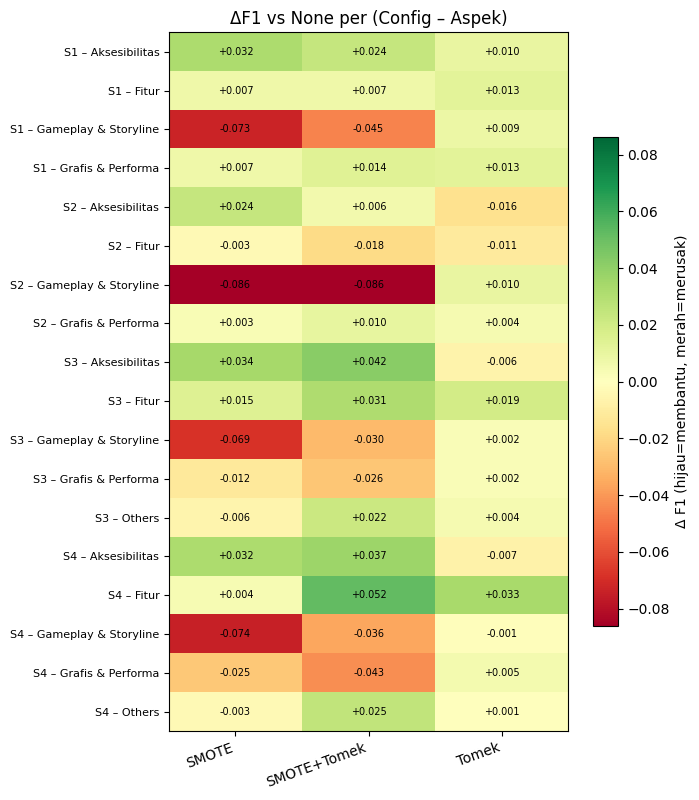

In [47]:
# Heatmap detail: ΔF1 tiap (config-aspek) x skenario
import numpy as np

hm = delta.copy()
hm.index = [f"{cfg.split(' ')[0]} – {asp}"
            for cfg, asp in zip(hm.index.get_level_values("ConfigLabel"),
                                hm.index.get_level_values("Aspek"))]

fig, ax = plt.subplots(figsize=(7, max(4, 0.45 * len(hm))))
vmax = np.nanmax(np.abs(hm.values))
im = ax.imshow(hm.values, cmap="RdYlGn", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(hm.columns)))
ax.set_xticklabels(hm.columns, rotation=20, ha="right")
ax.set_yticks(range(len(hm.index)))
ax.set_yticklabels(hm.index, fontsize=8)
for i in range(len(hm.index)):
    for j in range(len(hm.columns)):
        v = hm.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:+.3f}", ha="center", va="center", fontsize=7)
ax.set_title("ΔF1 vs None per (Config – Aspek)")
fig.colorbar(im, ax=ax, label="Δ F1 (hijau=membantu, merah=merusak)", shrink=0.7)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "balancing_delta_heatmap.png"),
            dpi=150, bbox_inches="tight")
plt.show()

### 6c. Rata-rata makro F1 per config

Satu angka per skenario per config (rata-rata F1 lintas aspek). Ringkas untuk
tabel utama, tapi baca bersama 6a/6b karena menyembunyikan variasi antar-aspek.

In [48]:
makro = (df.pivot_table(index="ConfigLabel", columns="Skenario",
                        values="f1", aggfunc="mean", observed=True)
           .round(4))
makro

Skenario,None,SMOTE,Tomek,SMOTE+Tomek
ConfigLabel,,,,
S1 (1000 – Tanpa negasi),0.7560,0.7492,0.7669,0.7556
S2 (1000 – Dengan negasi),0.7623,0.7466,0.7590,0.7402
S3 (3000 – Tanpa negasi),0.7800,0.7724,0.7843,0.7879
S4 (3000 – Dengan negasi),0.7847,0.7714,0.7908,0.7917


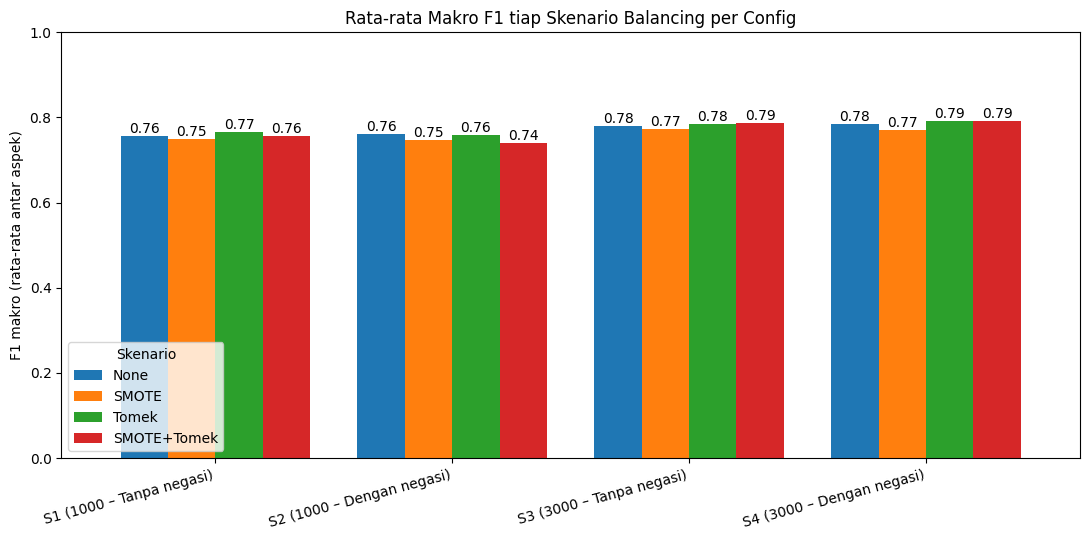

In [49]:
ax = makro.plot(kind="bar", figsize=(11, 5.5), width=0.8)
ax.set_ylabel("F1 makro (rata-rata antar aspek)")
ax.set_xlabel("")
ax.set_title("Rata-rata Makro F1 tiap Skenario Balancing per Config")
ax.set_ylim(0, 1)
ax.legend(title="Skenario")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "balancing_makro_per_config.png"), dpi=150)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='edge')
plt.show()

### 6d. Tambahkan hasil balancing ke file Excel

In [50]:
with pd.ExcelWriter(xlsx_path, engine="openpyxl", mode="a",
                    if_sheet_exists="replace") as xw:
    absolut.to_excel(xw, sheet_name="Balancing Absolut")
    delta.round(4).to_excel(xw, sheet_name="Balancing Delta vs None")
    delta_ringkas.to_excel(xw, sheet_name="Balancing Delta Ringkas")
    makro.to_excel(xw, sheet_name="Balancing Makro")

print("Sheet balancing ditambahkan ke:", xlsx_path)

Sheet balancing ditambahkan ke: /content/outputs/perbandingan_skenario.xlsx


## 7. Catatan

- Ubah `CONFIG_META` bila mapping data/preprocessing berbeda.
- `is_best` mengikuti `best_scenario` yang sudah tercatat di tiap file JSON.
- Metrik lain (accuracy, precision, recall) tersimpan di sheet **Data Lengkap** —
  ganti `values="f1"` pada pivot untuk memvisualisasikan metrik lain.